# IIR introduction

In [2]:
# import
import matplotlib.pyplot as plt; from scipy.io import wavfile
%run ./init.py

## Les limitations d'un filtre FIR

Les filtres FIR permettent de manipuler les signaux audios.  

$y[n] = 0.5(x[n] - x[n-1])$ permet par exemple de filtrer les basses fréquences du signal.

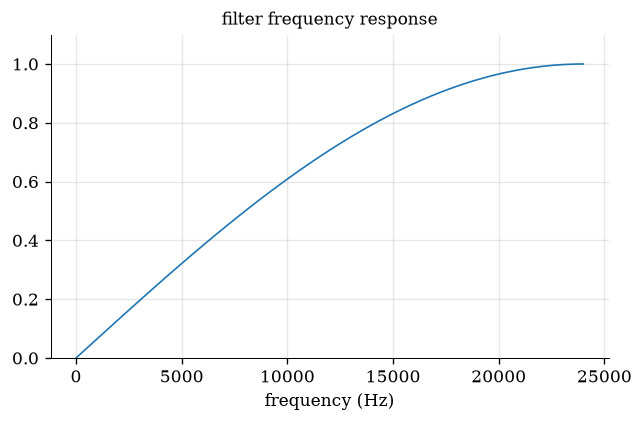

In [3]:
# load audio file
x, fs = wavread('../assets/drums.wav')
t = np.arange(0, len(x)) / fs

# play input
playsound(x, fs)

# create filter
h = np.array([0.5, -0.5])
# n = 20; h = np.ones(n)/n

# get filter response
n = 100
H = np.fft.rfft(h, n)
freqs = np.fft.rfftfreq(n, 1/fs)

# plot filter response
plt.plot(freqs, np.abs(H));
plt.ylim([0, 1.1]); plt.xlabel('frequency (Hz)'); plt.title('filter frequency response'); plt.show()

# apply filter
y = np.convolve(x, h)

# play output
playsound(y, fs)

Pour obtenir un comportement plus marqué/sélectif, il faut généralement augmenter la taille du FIR (i.e. le nombre de "taps").

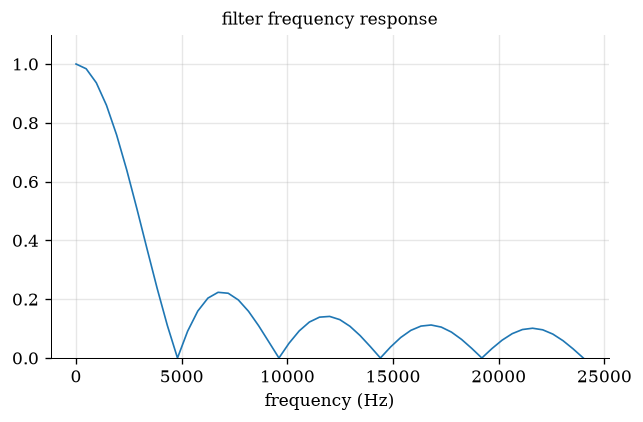

In [13]:
# load audio file
x, fs = wavread('../assets/drums.wav')

# play input
playsound(x, fs)

# create filter
n = 10; h = np.ones(n)/n

# # create filter (debug)
# numtaps = 25
# h = scipy.signal.firwin(numtaps=25, cutoff=1000, fs=fs)

# apply filter
y = np.convolve(x, h)

# get filter response
n = 100
H = np.fft.rfft(h, n)
freqs = np.fft.rfftfreq(n, 1/fs)

# plot filter response
plt.plot(freqs, np.abs(H)); 
plt.ylim([0, 1.1]); plt.xlabel('frequency (Hz)'); plt.title('filter frequency response'); plt.show()

# play output
playsound(y, fs)

Cette opération peut vite devenir coûteuse (peut importe l'approche : longue convolution ou large TF).

Résultat intéressant : utiliser une **récursion** permet d'obtenir des "réponses équivalentes" très longues (infinies) tout en gardant un coût de calcul global très faible.

Exemple : $y[n] = 0.1.x[n] + 0.9.y[n-1]$

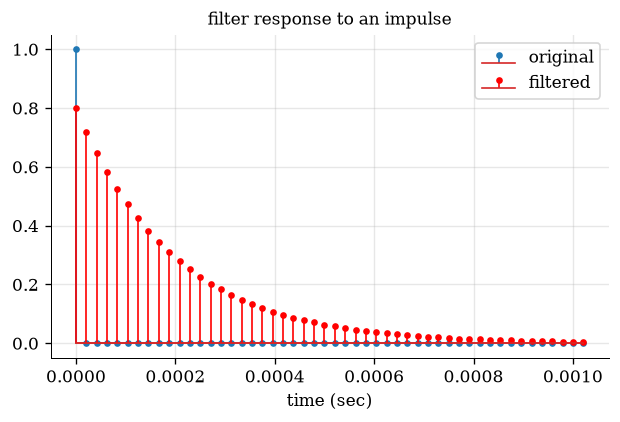

In [5]:
# filter
def filter(x, b, a):
    y = np.zeros_like(x)
    y[0] = b * x[0]
    for i_sample in range(1, len(x)):
        y[i_sample] = b * x[i_sample] - a * y[i_sample - 1]
    return y

# create input signal
x = np.zeros(50); x[0] = 1; t = np.arange(0, len(x))/fs

# filter
b = 0.8; a = -0.9
y = filter(x, b, a)

# plot
plt.stem(t, x, label = 'original')
plt.stem(t, y, 'r', label = 'filtered')
plt.xlabel('time (sec)'); plt.title('filter response to an impulse'); plt.legend(); plt.show();

pour la suite, on utilisera la function `lfilter` qui permet de simplifier l'implémentation :

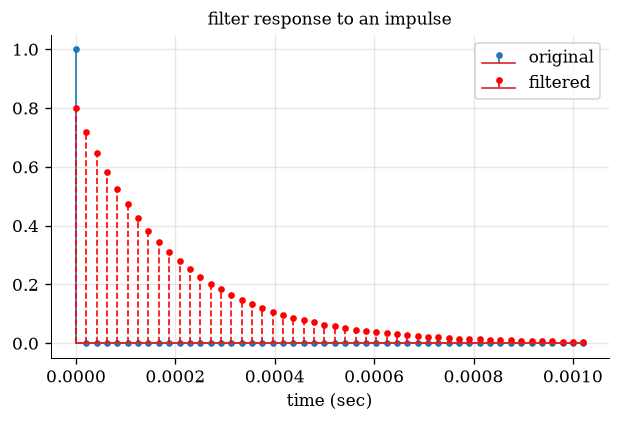

In [6]:
# filter
y = scipy.signal.lfilter([b], [1, a], x)

# plot
plt.stem(t, x, label = 'original')
plt.stem(t, y, '--r', label = 'filtered')
plt.xlabel('time (sec)'); plt.title('filter response to an impulse'); plt.legend(); plt.show();

Avec les bonnes valeurs de coefficients, on pourrait obtenir des filtres IIR très utiles pour un coût de calcul dérisoire par rapport à leurs "équivalent" FIR. Les IIRs sont très souvent utilisés à la place des FIRs pour les opérations de filtrage courantes (EQ, lowpass, etc.).

L'implémentation ci-dessous est un peu prématurée, mais elle permet de se faire une idée de la différence d'"efficacité" entre les filtres FIR et les IIR.

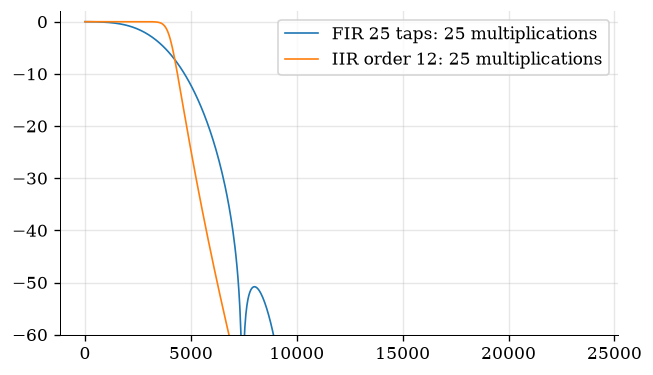

In [10]:
from scipy import signal

fs = 48000
fc = 4000

# FIR: needs many coefficients for a reasonably sharp LPF
numtaps = 25
b_fir = scipy.signal.firwin(numtaps=numtaps, cutoff=fc, fs=fs)
a_fir = [1]

# IIR: Butterworth
order = 12
b_iir, a_iir = scipy.signal.butter(N=order, Wn=fc, btype='low', fs=fs)

f, H_fir = signal.freqz(b_fir, a_fir, fs=fs)
f, H_iir = signal.freqz(b_iir, a_iir, fs=fs)

plt.plot(f, 20*np.log10(abs(H_fir)), label=f'FIR {numtaps} taps: {numtaps} multiplications')
plt.plot(f, 20*np.log10(abs(H_iir)), label=f'IIR order {order}: {order*2+1} multiplications')
plt.ylim([-60, 2]); plt.legend(); plt.show()

Il nous faut un framework théorique pour systématiser la recherche de ces coefficients.
Explorons d'abord de quoi les IIRs sont capables une fois qu'on maîtrisera ce framework.

## IIR coefficients cookbook

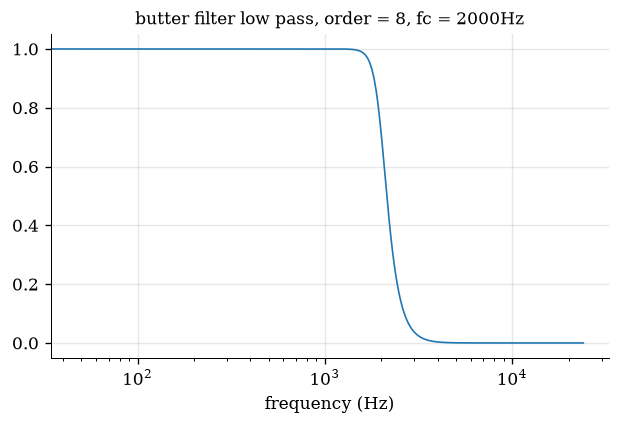

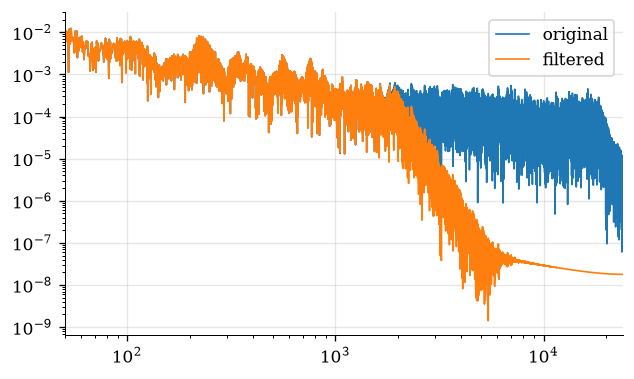

In [8]:
# define filter
btype = 'low'; ftype = 'butter'; Wn = 2000; order = 8
# btype = 'high'; ftype = 'butter'; Wn = 4000; order = 4
# btype = 'bandpass'; ftype = 'butter'; Wn = [2000, 4000]; order = 4
# btype = 'bandstop'; ftype = 'butter'; Wn = [300, 700]; order = 4

# load audio file
audio_in, fs = wavread('../assets/drums.wav')

# play
playsound(audio_in, fs)

# get filter coefficients
b, a = scipy.signal.iirfilter(N=order, Wn=Wn, fs=fs, btype=btype, ftype=ftype)

# plot frequency response
freqs, H = scipy.signal.freqz(b, a, fs=fs)
plt.plot(freqs, np.abs(H))
plt.xlabel('frequency (Hz)');
plt.title(f'{ftype} filter {btype} pass, order = {order}, fc = {Wn}Hz');
plt.xscale('log')
plt.show()

# filter signal 
audio_out = scipy.signal.lfilter(b, a, audio_in)

# fft
n = len(audio_in)
audio_in_fft = np.fft.rfft(audio_in, n) / (n/2)
audio_out_fft = np.fft.rfft(audio_out, n) / (n/2)
f = np.fft.rfftfreq(n, 1/fs)

# plot
plt.plot(f, np.abs(audio_in_fft), label = 'original')
plt.plot(f, np.abs(audio_out_fft), label = 'filtered')

# format plot
plt.xscale('log'); plt.yscale('log')
plt.xlim([50, fs/2])
plt.legend()
plt.show()

# play 
playsound(y, fs)